# Praktikum 1 - Pra Pengolahan Data dan Ekstraksi Fitur (Data Terstruktur)

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

Pada praktikum pertama di Jobsheet 3 ini saya melakukan pra pengolahan data (pengecekan dan imputasi nilai kosong) pada dataset `Titanic-Dataset.csv`, lalu dilanjutkan dengan perekayasaan dan ekstraksi fitur baru (`FamilySize`, `Title`, `AgeBin`, `CabinDeck`, dan `FarePerPerson`) serta memvisualisasikan pengaruhnya terhadap tingkat keselamatan penumpang (`Survived`).

### Langkah 1 - Load Data

Mengimpor library `pandas` dan memuat dataset `Titanic-Dataset.csv` ke dalam DataFrame, kemudian menampilkan 5 baris teratas.

In [1]:
import pandas as pd

dpath = 'Titanic-Dataset.csv'
df = pd.read_csv(dpath)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Langkah 2 - Pengecekan Data

Memeriksa struktur tipe data tiap kolom dengan `df.info()` dan menghitung jumlah data yang kosong (`NaN`) pada masing-masing kolom.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [3]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Dari pengecekan di atas, terdapat 3 kolom yang memiliki nilai kosong dari total 891 baris data, yaitu `Age` sebanyak 177 data, `Cabin` sebanyak 687 data, dan `Embarked` sebanyak 2 data.

### Langkah 3 - Imputasi

Melakukan pengisian nilai yang hilang (*imputation*) dengan strategi:
- `Age` diisi dengan nilai rata-rata (*mean*).
- `Cabin` diisi dengan string `"DECK"` (asumsi penumpang tanpa nomor kabin berada di dek kapal).
- `Embarked` diisi dengan nilai modus (*mode*).

In [4]:
# Age - mean
df['Age'] = df['Age'].fillna(value=df['Age'].mean())

# Cabin - "DECK"
df['Cabin'] = df['Cabin'].fillna(value="DECK")

# Embarked - modus
df['Embarked'] = df['Embarked'].fillna(value=df['Embarked'].mode()[0])

### Langkah 4 - Validasi Hasil

Memastikan seluruh kolom sudah tidak memiliki nilai kosong dan menampilkan 10 baris pertama hasil imputasi.

In [5]:
df.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [6]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.2500,DECK,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000000,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.9250,DECK,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.0500,DECK,S
5,6,0,3,"Moran, Mr. James",male,29.699118,0,0,330877,8.4583,DECK,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.000000,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.000000,3,1,349909,21.0750,DECK,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.000000,0,2,347742,11.1333,DECK,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.000000,1,0,237736,30.0708,DECK,C


### Langkah 5 - Ekstraksi Fitur

Mengekstraksi 5 fitur baru dari atribut yang sudah ada:
1. `FamilySize`: total anggota keluarga di kapal (`SibSp + Parch + 1`).
2. `Title`: mengambil gelar dari kolom `Name` menggunakan regular expression dan mengelompokkan gelar langka ke dalam `'Rare'`.
3. `AgeBin`: mengelompokkan usia (`Age`) ke dalam 5 rentang kategori (`Child`, `Teen`, `YoungAdult`, `Adult`, `Senior`).
4. `CabinDeck`: mengambil karakter pertama dari kolom `Cabin`.
5. `FarePerPerson`: membagi harga tiket (`Fare`) dengan `FamilySize`.

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# === EKSTRAKSI FITUR ===

# 1. FamilySize: jumlah keluarga di kapal (SibSp + Parch + diri sendiri)
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

# 2. Title: ambil gelar dari kolom Name (Mr, Mrs, Miss, Master, dll.)
df["Title"] = df["Name"].str.extract(r',\s*([^\.]+)\.', expand=False)
title_mapping = {
    "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
    "Lady": "Rare", "Countess": "Rare", "Capt": "Rare", "Col": "Rare",
    "Don": "Rare", "Dr": "Rare", "Major": "Rare", "Rev": "Rare",
    "Sir": "Rare", "Jonkheer": "Rare", "Dona": "Rare"
}
df["Title"] = df["Title"].replace(title_mapping)

# 3. AgeBin: kelompokkan usia menjadi kategori
df["AgeBin"] = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 100],
                      labels=["Child", "Teen", "YoungAdult", "Adult", "Senior"])

# 4. CabinDeck: ambil huruf pertama dari kolom Cabin
df["CabinDeck"] = df["Cabin"].astype(str).str[0]

# 5. Fare per person: bagi harga tiket dengan jumlah keluarga
df["FarePerPerson"] = df["Fare"] / df["FamilySize"]

print("Hasil Ekstraksi fitur:")
df[["Name", "Title", "Age", "AgeBin", "FamilySize", "Cabin", "CabinDeck", "FarePerPerson"]].head()

Hasil Ekstraksi fitur:


,Name,Title,Age,AgeBin,FamilySize,Cabin,CabinDeck,FarePerPerson
0,"Braund, Mr. Owen Harris",Mr,22.0,YoungAdult,2,DECK,D,3.62500
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs,38.0,Adult,2,C85,C,35.64165
2,"Heikkinen, Miss. Laina",Miss,26.0,YoungAdult,1,DECK,D,7.92500
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,35.0,YoungAdult,2,C123,C,26.55000
4,"Allen, Mr. William Henry",Mr,35.0,YoungAdult,1,DECK,D,8.05000


### Langkah 6 - Visualisasi Hasil Ekstraksi Fitur

Memvisualisasikan proporsi keselamatan (`Survival Rate`) untuk setiap fitur hasil ekstraksi (`FamilySize`, `Title`, `AgeBin`, dan `CabinDeck`) menggunakan grafik batang Seaborn.

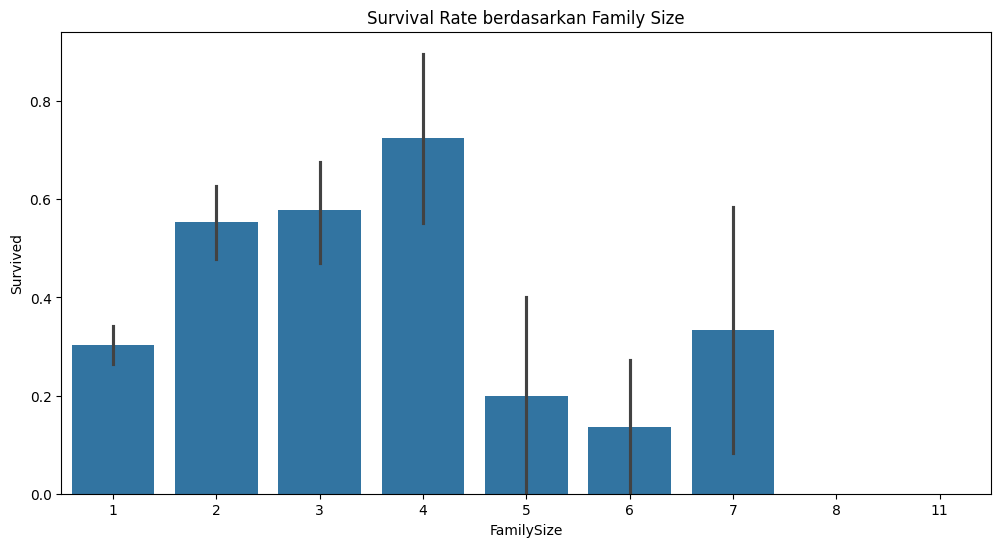

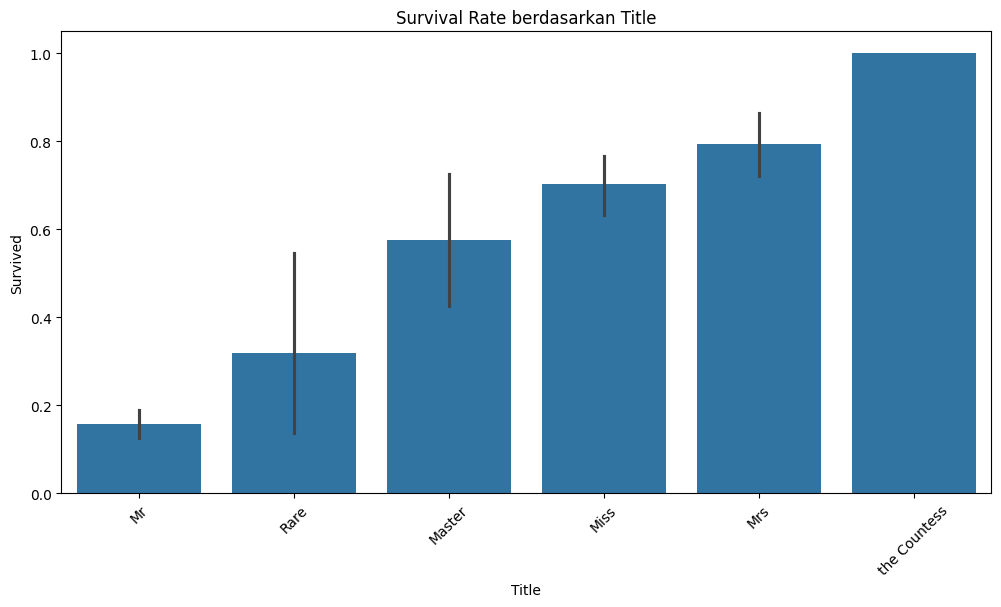

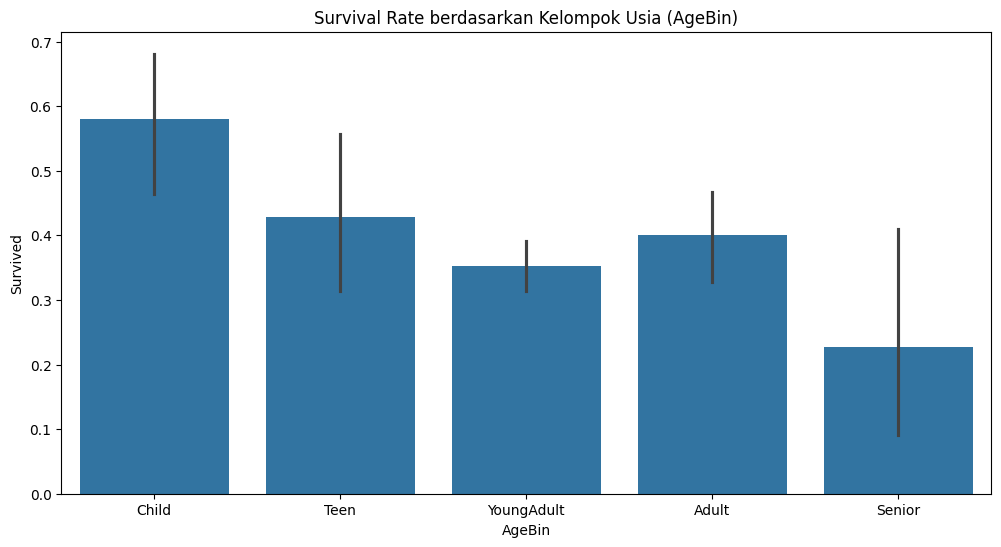

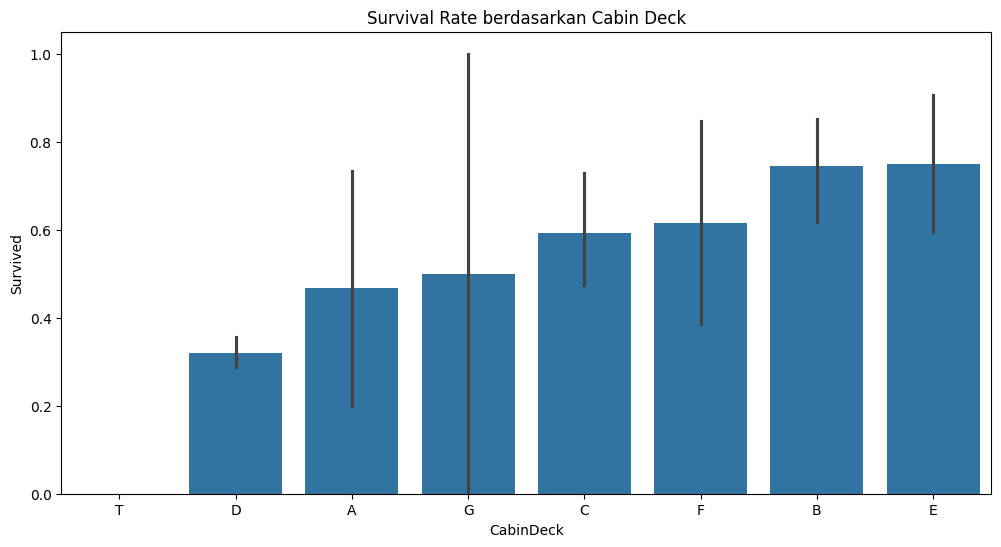

In [9]:
# === VISUALISASI FITUR HASIL EKSTRAKSI ===
plt.figure(figsize=(12, 6))
sns.barplot(x="FamilySize", y="Survived", data=df)
plt.title("Survival Rate berdasarkan Family Size")
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(x="Title", y="Survived", data=df, order=df.groupby("Title")["Survived"].mean().sort_values().index)
plt.title("Survival Rate berdasarkan Title")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(x="AgeBin", y="Survived", data=df, order=["Child", "Teen", "YoungAdult", "Adult", "Senior"])
plt.title("Survival Rate berdasarkan Kelompok Usia (AgeBin)")
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(x="CabinDeck", y="Survived", data=df, order=df.groupby("CabinDeck")["Survived"].mean().sort_values().index)
plt.title("Survival Rate berdasarkan Cabin Deck")
plt.show()

Dari keempat visualisasi fitur hasil ekstraksi di atas, kita bisa melihat beberapa pola menarik yang tadinya tidak langsung terlihat pada kolom mentah:
1. **FamilySize:** Penumpang yang pergi bersama keluarga kecil berukuran 2 sampai 4 orang memiliki peluang selamat paling tinggi (puncaknya pada `FamilySize = 4` sebesar `72.4%`, disusul ukuran `3` sebesar `57.8%` dan `2` sebesar `55.3%`). Sebaliknya, penumpang yang bepergian sendirian (`FamilySize = 1`, survival rate `30.4%`) maupun keluarga besar (`>= 5` orang) memiliki tingkat keselamatan yang jauh lebih rendah.
2. **Title:** Gelar yang diekstrak dari kolom `Name` sangat membantu membedakan peluang selamat. Penumpang perempuan (`Mrs` sebesar `79.4%`, `Miss` sebesar `70.3%`, serta `the Countess` `100%`) dan anak laki-laki (`Master` sebesar `57.5%`) punya peluang selamat tinggi, sedangkan laki-laki dewasa (`Mr`) hanya memiliki survival rate `15.7%`.
3. **AgeBin:** Kelompok usia anak-anak (`Child`, 0–12 tahun) memiliki rata-rata keselamatan tertinggi (`58.0%`), sedangkan kelompok lansia (`Senior`, >60 tahun) memiliki rata-rata keselamatan paling rendah (`22.7%`).
4. **CabinDeck:** Penumpang pada kabin dek `E` (`75.0%`), `B` (`74.5%`), `F` (`61.5%`), dan `C` (`59.3%`) memiliki tingkat keselamatan tinggi. Sementara kategori `'D'` terlihat cukup rendah (`32.1%`) karena selain berisi kabin dek D asli, seluruh penumpang tanpa nomor kabin yang pada Langkah 3 diimputasi menjadi `"DECK"` ikut terambil huruf pertamanya sebagai `'D'`.